# Real dataset: Sea surface temperature in the Massachusetts and Cape Cod Bays, spatio-temporal model

In [1]:
import os
import sys
sys.path.append(os.path.abspath('../python_files'))
from utils import *
from Gaussian_Process import *
from Multifidelity_GP_AR1 import *

import matplotlib
import matplotlib.pyplot as plt  # version 3.10.0
import geopandas as gpd          # version 1.1.1
import pickle
import time

In [2]:
from threadpoolctl import threadpool_info
for lib in threadpool_info():
    print(lib["internal_api"], lib["version"], lib["num_threads"])

openblas 0.3.27 22
openblas 0.3.28 22


## Load dataset

In [3]:
notebook_dir = os.getcwd()
data_dir = os.path.abspath(os.path.join(notebook_dir, '../data/data_cape_cod'))
plot_dir = os.path.abspath(os.path.join(notebook_dir, '../plots'))

In [4]:
N_L = 2526
N_H = 195
D = 3

path_LFtr = "../data/data_cape_cod/Data_Train_LF_Fig8.txt"
LF_train_data = np.loadtxt(path_LFtr)
X_L, z_L = LF_train_data[:,:-1], LF_train_data[:,-1].reshape(-1,1)
check_shape('X_L', X_L, (N_L,D))  # Must contain triplets (longitude, latitude, time)
check_shape('z_L', z_L, (N_L,1))  # Must contain a scalar value (temperature)
path_HFtr = "../data/data_cape_cod/Data_Train_HF_Fig8.txt"
HF_train_data = np.loadtxt(path_HFtr)
X_H, z_H = HF_train_data[:,:-1], HF_train_data[:,-1].reshape(-1,1)
check_shape('X_H', X_H, (N_H,D))
check_shape('z_H', z_H, (N_H,1))

X_L: got (2526, 3), expected (2526, 3)
z_L: got (2526, 1), expected (2526, 1)
X_H: got (195, 3), expected (195, 3)
z_H: got (195, 1), expected (195, 1)


In [5]:
np.loadtxt("../data/data_cape_cod/Stat_F13_HF.txt")

array([[ 35.333241 ,   1.2660248],
       [ 79.352419 ,   1.0871711],
       [103.29287  ,   4.2861266],
       [131.29019  ,  11.078741 ],
       [174.5694   ,  13.653323 ],
       [202.29098  ,  20.931234 ],
       [230.28488  ,  18.856335 ],
       [252.30081  ,  19.217522 ],
       [294.33157  ,  12.891583 ],
       [408.44477  ,   3.2830899],
       [448.30144  ,   5.429697 ],
       [474.28866  ,   7.048955 ],
       [504.27961  ,   9.8841295],
       [538.28699  ,  14.978383 ],
       [573.28108  ,  20.410906 ],
       [601.29014  ,  18.84911  ],
       [642.29472  ,  15.702991 ],
       [671.29924  ,  12.377281 ]])

In [6]:
# Check the first entries
X_L[0:10,:], z_L[0:10,:]

(array([[-70.937492,  42.395832, 121.      ],
        [-70.895828,  42.4375  , 121.      ],
        [-70.895828,  42.395832, 121.      ],
        [-70.854164,  42.479168, 121.      ],
        [-70.854164,  42.4375  , 121.      ],
        [-70.854164,  42.354168, 121.      ],
        [-70.812492,  42.479168, 121.      ],
        [-70.812492,  42.4375  , 121.      ],
        [-70.812492,  42.354168, 121.      ],
        [-70.770828,  42.479168, 121.      ]]),
 array([[7.7599998],
        [7.8699998],
        [7.7599998],
        [8.6149998],
        [8.4399998],
        [8.2899998],
        [8.6149998],
        [8.7599998],
        [8.2899998],
        [8.6049998]]))

In [7]:
X_H[0:10,:], z_H[0:10,:]

(array([[-70.453333,  41.850833,  39.460417],
        [-70.453333,  41.850833,  79.558333],
        [-70.453333,  41.850833, 102.51875 ],
        [-70.453333,  41.850833, 129.42222 ],
        [-70.453333,  41.850833, 175.50903 ],
        [-70.453333,  41.850833, 202.41458 ],
        [-70.453333,  41.850833, 230.43542 ],
        [-70.453333,  41.850833, 253.47083 ],
        [-70.453333,  41.850833, 294.55    ],
        [-70.453333,  41.850833, 406.55625 ]]),
 array([[ 1.0272],
        [ 1.5766],
        [ 5.1119],
        [ 9.2891],
        [15.7563],
        [20.9161],
        [21.9306],
        [19.0262],
        [14.0604],
        [ 4.4181]]))

In [8]:
time_test = np.arange(2., 732., 1.)
N_test = len(time_test)  # = 2*365

In [9]:
def Normalize(X, m, M, shift):
    """ Shifts a dataset X of a certain amount (typically its mean) and normalizes it using a min and max value.
        Args: 
            X ((N,D) array): Input set.
            m ((D,) array): Min value.
            M ((D,) array): Max value.
        Returns: (N,D) array: Transformed data set.
        """
    return (X - shift) / (M - m)

def deNormalize(X, m, M, shift):
    """ Reciprocal operation of Normalize.
        Args: 
            X ((N,D) array): Input set.
            m ((D,) array): Min value.
            M ((D,) array): Max value.
        Returns: (N,D) array: Transformed data set.
    """
    return (M - m) * X + shift

In [10]:
mXL, minXL, maxXL = np.mean(X_L, axis=0), np.min(X_L, axis=0), np.max(X_L, axis=0)
mzL, minzL, maxzL = np.mean(z_L, axis=0), np.min(z_L, axis=0), np.max(z_L, axis=0)
# The model is trained on the normalized inputs and outputs.
norm_X_L = Normalize(X_L, minXL, maxXL, mXL)  
norm_z_L = Normalize(z_L, minzL, maxzL, mzL) 
cov_correction = ((maxzL - minzL)**2)[0]   # correction factor on the predictive variance due to output normalization

In [11]:
cov_correction

np.float64(555.5448575740008)

In [12]:
stations = ['F13', 'F29', 'N04', 'F02', 'N07']
# Positions of the stations for temporal predictions (longitude, latitude)
st_positions = np.array([[-7.0735000e+01, 4.2268333e+01], 
                         [-7.0290000e+01, 4.2116667e+01],
                         [-7.0736500e+01, 4.2443833e+01],
                         [-7.0228333e+01, 4.1908167e+01],
                         [-7.0706167e+01, 4.2356333e+01]])

## Cape Cod Bay maps

In [13]:
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection

CRS : None
Columns: Index(['geometry'], dtype='object')


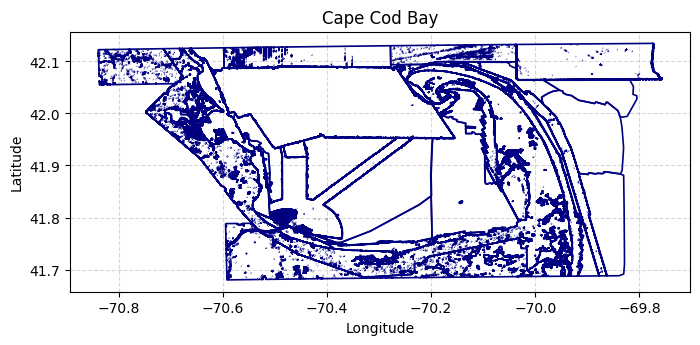

In [14]:
shapefile_path = os.path.join(data_dir, "CapeCodBay_Source.shp")
gdf_code = gpd.read_file(shapefile_path)
print("CRS :", gdf_code.crs)
print("Columns:", gdf_code.columns)
if gdf_code.crs and gdf_code.crs.to_string() != "EPSG:4326":
    gdf_code = gdf_code.to_crs(epsg=4326)
fig, ax = plt.subplots(figsize=(8, 8))
gdf_code.boundary.plot(ax=ax, color="navy", linewidth=1.2)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Cape Cod Bay")
ax.set_aspect("equal", adjustable="box")
ax.grid(True, linestyle="--", alpha=0.5)
plt.show()

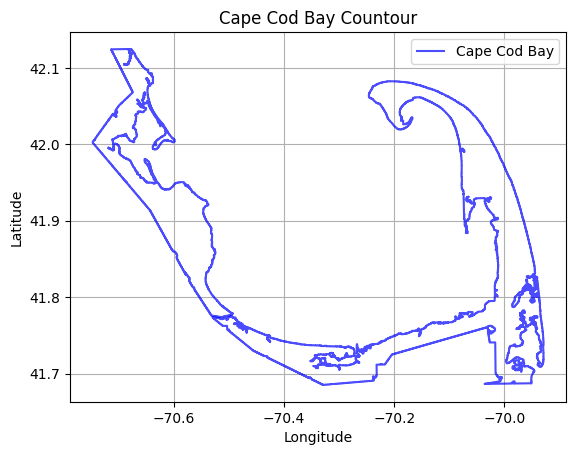

In [15]:
geom_code = gdf_code.iloc[29].geometry
geom_codebis = gdf_code.iloc[16].geometry
plt.figure()
def plot_largest_polygons(geom, top_n=2, color='blue', alpha=0.5, label=None):
    """ Plots the "top_n" largest (surface-wise) polygones
    """
    first = True
    if geom.geom_type == 'MultiPolygon':
        largest_polys = sorted(geom.geoms, key=lambda p: p.area, reverse=True)[:top_n]
        for poly in largest_polys:
            x, y = poly.exterior.xy
            plt.plot(x, y, color=color, alpha=alpha, label=label if first else None)
            first = False
    elif geom.geom_type == 'Polygon':
        x, y = geom.exterior.xy
        plt.plot(x, y, color=color, alpha=alpha, label=label)

def plot_largest_polygons_ax(ax, geom, top_n=2, color='blue', alpha=0.5, label=None):
    """ Subplot version
    """
    first = True
    if geom.geom_type == 'MultiPolygon':
        largest_polys = sorted(geom.geoms, key=lambda p: p.area, reverse=True)[:top_n]
        for poly in largest_polys:
            x, y = poly.exterior.xy
            ax.plot(x, y, color=color, alpha=alpha, label=label if first else None)
            first = False
    elif geom.geom_type == 'Polygon':
        x, y = geom.exterior.xy
        ax.plot(x, y, color=color, alpha=alpha, label=label)
plot_largest_polygons(geom_code, top_n=2, color='blue', alpha=0.7, label='Cape Cod Bay')
#plot_largest_polygons(geom_codebis, top_n=2, color='blue', alpha=0.7, label=None)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Cape Cod Bay Countour')
plt.grid()
plt.legend()
#plt.axis('equal')
# plt.xlim(-71, -69.9)
# plt.ylim(41.7, 42.6) 
plt.show()

In [16]:
shapefile_path = os.path.join(data_dir, "MassBay_Source.shp")
gdf_mass = gpd.read_file(shapefile_path)
print("CRS :", gdf_mass.crs)
print("Columns:", gdf_mass.columns)
if gdf_mass.crs and gdf_mass.crs.to_string() != "EPSG:4326":
    gdf_mass = gdf_mass.to_crs(epsg=4326)
# fig, ax = plt.subplots(figsize=(8, 8))
# gdf_mass.boundary.plot(ax=ax, color="navy", linewidth=1.2)
# ax.set_xlabel("Longitude")
# ax.set_ylabel("Latitude")
# ax.set_title("Massachusetts Bay")
# ax.set_aspect("equal", adjustable="box")
# ax.grid(True, linestyle="--", alpha=0.5)
# plt.show()

CRS : None
Columns: Index(['geometry'], dtype='object')


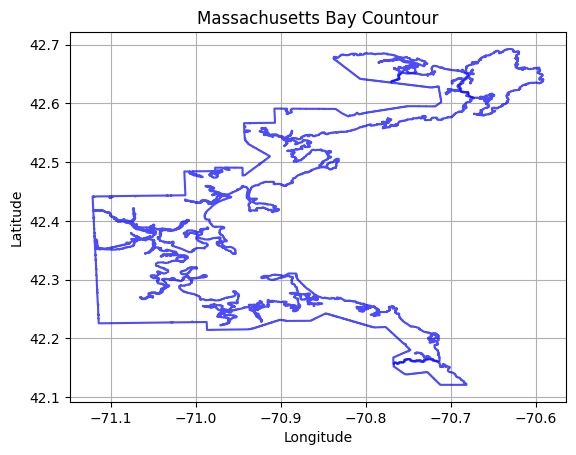

In [17]:
geom_mass = gdf_mass.iloc[27].geometry
plt.figure()
plot_largest_polygons(geom_mass, top_n=4, color='blue', alpha=0.7, label='Massachusetts Bay')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Massachusetts Bay Countour')
plt.grid()
#plt.axis('equal')
# plt.xlim(-71, -69.9)
# plt.ylim(41.7, 42.6) 
plt.show()

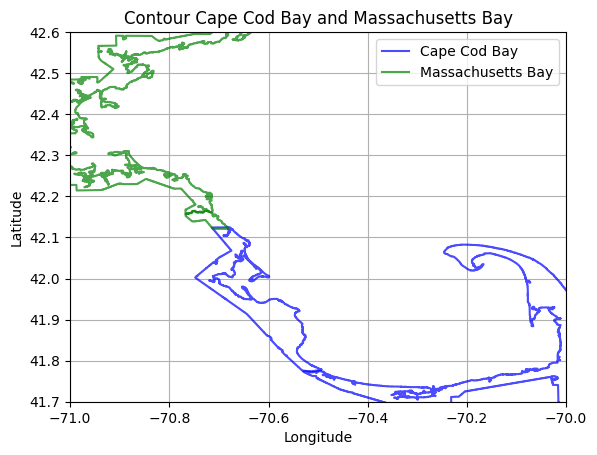

In [18]:
#plt.figure(figsize=(8, 8))
plot_largest_polygons(geom_code, top_n=2, color='blue', alpha=0.7, label='Cape Cod Bay')
#plot_largest_polygons(geom_codebis, top_n=1, color='blue', alpha=0.7, label=None)
plot_largest_polygons(geom_mass, top_n=4, color='green', alpha=0.7, label='Massachusetts Bay')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Contour Cape Cod Bay and Massachusetts Bay')
plt.grid()
plt.legend()
plt.xlim(-71, -70)
plt.ylim(41.7, 42.6) 
#plt.axis('equal')
plt.show()

In [19]:
def plot_bays(ax, geom_code, geom_mass, title=None, sea_color='lightblue', land_color='white'):
    all_polys = []
    for geom in [geom_code, geom_mass]:
        if geom.geom_type == 'Polygon':
            all_polys.append(geom)
        elif geom.geom_type == 'MultiPolygon':
            all_polys.extend(geom.geoms)
    all_polys = sorted(all_polys, key=lambda p: p.area, reverse=True)[:6]
    rect_coords = [[-71, 41.7], [-70, 41.7], [-70, 42.6], [-71, 42.6]]
    patches = [Polygon(rect_coords, closed=True)]
    for poly in all_polys:
        patches.append(Polygon(list(poly.exterior.coords), closed=True))
    rectangles = [
        [[-71, 41.7], [-70.8, 41.7], [-70.8, 42.25], [-71, 42.25]],
        [[-71, 42.47], [-70.9, 42.47], [-70.9, 42.58], [-71, 42.58]],
        [[-70.81, 42.2], [-70.73, 42.2], [-70.73, 41.7], [-70.81, 41.7]],
        [[-70.8, 42.2], [-70.762, 42.2], [-70.762, 42.23], [-70.8, 42.23]]
    ]
    for rect in rectangles:
        patches.append(Polygon(rect, closed=True))
    triangles = [
        [[-70.3, 41.7], [-70, 41.7], [-70, 41.78]],
        [[-70.8, 41.7], [-70.37, 41.7], [-70.8, 41.9]],
        [[-70.73, 42.016], [-70.73, 42.15], [-70.67, 42.065]],
        [[-70.73, 42.01], [-70.73, 41.75], [-70.49, 41.75]]
    ]
    for tri in triangles:
        patches.append(Polygon(tri, closed=True))
    collection = PatchCollection(patches, facecolor=[sea_color] + [land_color] * (len(all_polys) + len(rectangles) + len(triangles)),
                                linewidths=1)
    # collection = PatchCollection(patches, facecolor=[sea_color] + [land_color]*(len(all_polys)+len(rectangles)+len(triangles)),
    #                          edgecolor=['blue'] + ['blue']*(len(all_polys)+len(rectangles)+len(triangles)), linewidths=1)
    ax.add_collection(collection)
    ax.set_xlim(-71, -70)
    ax.set_ylim(41.7, 42.58)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_title(title)
    #ax.set_aspect('equal')
    ax.grid(True)

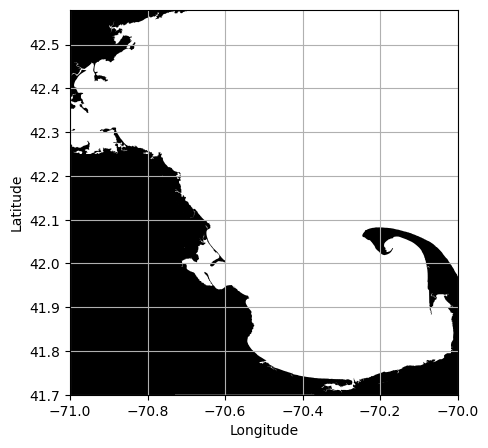

In [20]:
fig, ax = plt.subplots(figsize=(5, 5))
plot_bays(ax, geom_code, geom_mass, title=None, sea_color='none', land_color='black')
plt.show()

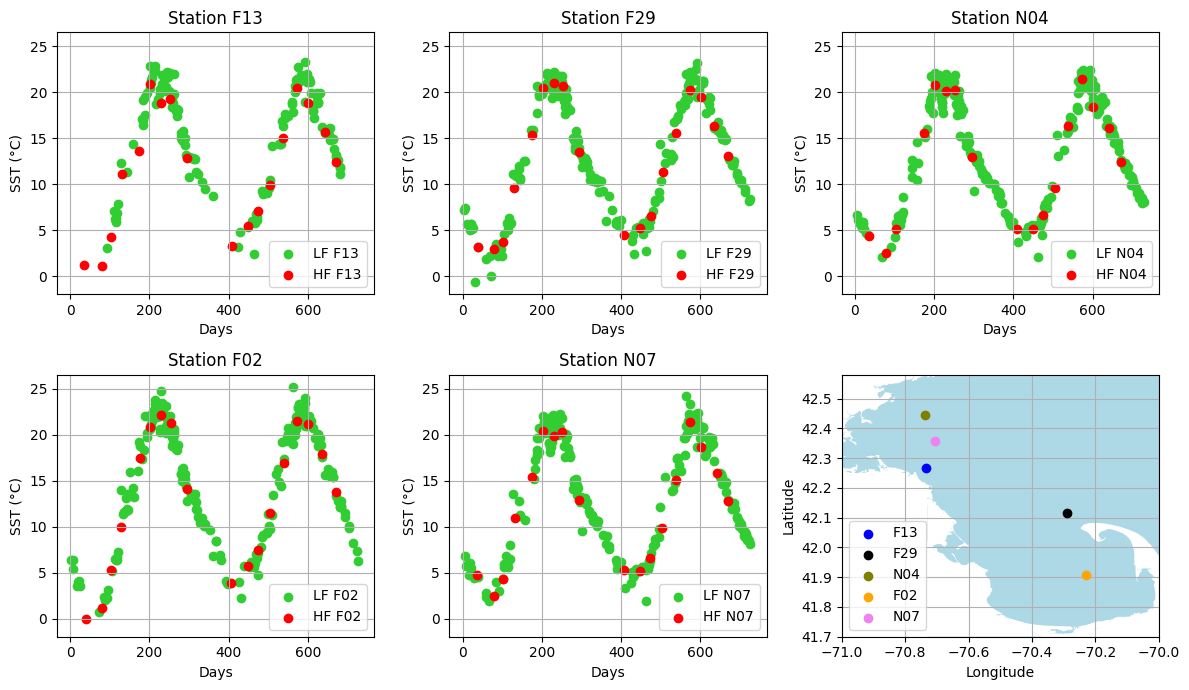

In [21]:
colors = ['blue', 'black', 'olive', 'orange', 'violet']
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.ravel() 
for ax in axes[1:5]:
    ax.sharex(axes[0])
    ax.sharey(axes[0])
for i in range(5):
    ax = axes[i]
    name = stations[i]
    path_LF = f"../data/data_cape_cod/Stat_{name}_LF.txt"
    LF_data = np.loadtxt(path_LF)
    X_Lsta, z_Lsta = LF_data[:,0], LF_data[:,1]
    path_HF = f"../data/data_cape_cod/Stat_{name}_HF.txt"
    HF_data = np.loadtxt(path_HF)
    X_Hsta, z_Hsta = HF_data[:,0], HF_data[:,1]
    ax.scatter(X_Lsta, z_Lsta, color='limegreen',label=f'LF {name}')
    ax.scatter(X_Hsta, z_Hsta, color='red',label=f'HF {name}')
    ax.set_xlabel('Days')
    ax.set_ylabel('SST (°C)')
    ax.legend(loc='lower right')
    ax.set_title(f'Station {name}')
    ax.grid()
ax = axes[5]
for i in range(5):
    name = stations[i]
    plot_bays(ax, geom_code, geom_mass)
    # plot_largest_polygons_ax(ax, geom_code, top_n=2, color='blue', alpha=0.7, label=None)
    # plot_largest_polygons_ax(ax, geom_mass, top_n=4, color='blue', alpha=0.7, label=None)
    ax.scatter(st_positions[i,0], st_positions[i,1], color=colors[i],label=f'{name}', zorder=5)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.legend(loc='lower left')
    ax.set_xlim(-71, -70)
    ax.set_ylim(41.7, 42.58)
    ax.grid(True)
plt.tight_layout()

## Train model

### LF

In [22]:
want_to_retrain = False     # if True, re-train the model, if False, loads the saved model.
want_to_save = False        # if True, save the re-trained model.
seed = 0
np.random.seed(seed)
verbose = True

In [23]:
theta_L = (np.max(norm_X_L, axis=0) - np.min(norm_X_L, axis=0)) / 2
mbasis_L = Constant_basis(None)
kernel_L = RBF_kernel(theta_L, None) 
zeta_L = np.array([0.])
eta_fnL = Homoscedastic(params=zeta_L)
gp_L = GPR(mbasis_L, kernel_L, norm_X_L, norm_z_L, noise='opt', eta_fn=eta_fnL)

In [24]:
n_starts = 10
n_cores = 1
namefile = os.path.join(data_dir, "capecod_LF-GP_model.pkl")
nametime = os.path.join(data_dir, "capecod_LF-GP_time.pkl")
if want_to_retrain:
    t1_lf = time.time()
    best, nlml_value = gp_L.fit(n_starts=n_starts, n_cores=n_cores, jitter=1e-10, rng_seed=seed, verbose=verbose)
    t2_lf = time.time()
    t_lf = t2_lf - t1_lf
    if want_to_save:
        with open(namefile, "wb") as f:
            pickle.dump(gp_L, f)
        with open(nametime, "wb") as f:
            pickle.dump(t_lf, f)
else:
    with open(namefile, "rb") as f:
        gp_L = pickle.load(f)
    with open(nametime, "rb") as f:
        t_lf = pickle.load(f)
print(gp_L)

Parameter Name      Value               
----------------------------------------
mean_params         [[-0.04186298]]     
kernel_variance     [0.022146]          
length_scale        [0.26854746 0.10691291 0.04958678]
eta_fn_params       [-5.79334719]       
noise_variance      [6.74957664e-05]    


In [25]:
print(t_lf)

770.937816619873


### MF-EM

In [26]:
want_to_retrain = False      # if True, re-train the model, if False, loads the saved model.
want_to_save = False       # if True, save the re-trained model.
seed = 0
np.random.seed(seed)
verbose = True

norm_X_H = Normalize(X_H, minXL, maxXL, mXL)
norm_z_H = Normalize(z_H, minzL, maxzL, mzL) 

In [27]:
theta_H =  (np.max(norm_X_H, axis=0) - np.min(norm_X_H, axis=0)) / 2
beta_H = np.array([[0.]])
beta_rho = np.array([[1.]])
sigma2_H = 1.
mbasis_H = Constant_basis(beta_H) 
scale = Constant_basis(beta_rho)
kernel_H = RBF_kernel(theta_H, sigma2_H)
zeta_H = np.array([0.])
eta_fnH = Homoscedastic(params=zeta_H)
gp_H = GPR(mbasis_H, kernel_H, norm_X_H, norm_z_H, noise='opt', eta_fn=eta_fnH)
MF_gp = Multifi_GP_AR1(gp_L, gp_H, scale)

In [28]:
n_starts = 10
n_cores = 1
EM_iter = 200
namefile = os.path.join(data_dir, "capecod_MF-GP_model.pkl")
nametime = os.path.join(data_dir, "capecod_MF-GP_time.pkl")
if want_to_retrain:
    t1_mf = time.time()
    best, nll = MF_gp.fit(EM_iter=EM_iter, n_starts=n_starts, n_cores=n_cores, jitter=1e-8, rng_seed=seed, verbose=verbose, tol=1e-10)
    t2_mf = time.time()
    t_mf = t2_mf - t1_mf
    if want_to_save:
        with open(namefile, "wb") as f:
            pickle.dump(MF_gp, f)
        with open(nametime, "wb") as f:
            pickle.dump(t_mf, f)
else:
    with open(namefile, "rb") as f:
        MF_gp = pickle.load(f)
    with open(nametime, "rb") as f:
        t_mf = pickle.load(f)

In [29]:
print(MF_gp)

Parameter Name      Value               
----------------------------------------
LF_mean_params      [[-0.04186298]]     
LF_kernel_variance  [0.022146]          
LF_length_scale     [0.26854746 0.10691291 0.04958678]
LF_eta_fn_params    [-5.79334719]       
LF_noise_variance   [6.74957664e-05]    
scaling_params      [[0.46580404]]      
HF_mean_params      [[-0.04361331]]     
HF_kernel_variance  [0.01952563]        
HF_length_scale     [0.713667   0.71885714 0.04350833]
HF_eta_fn_params    [-4.27779518]       
HF_noise_variance   [0.00027088]        


In [30]:
print(t_mf)

130.486581325531


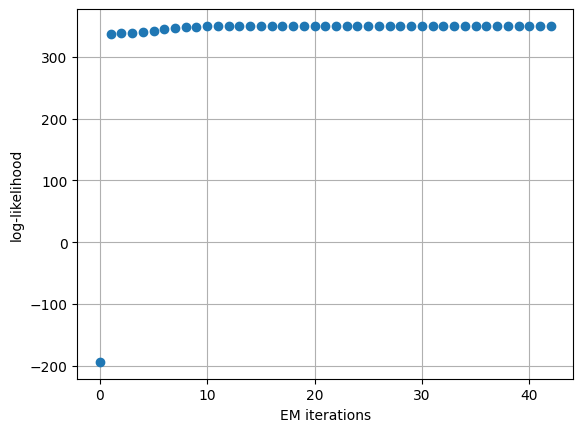

In [31]:
EM_ll = MF_gp.log_lik_values
plt.plot(EM_ll, 'o')
plt.xlabel('EM iterations')
plt.ylabel('log-likelihood')
plt.grid()
plt.show()

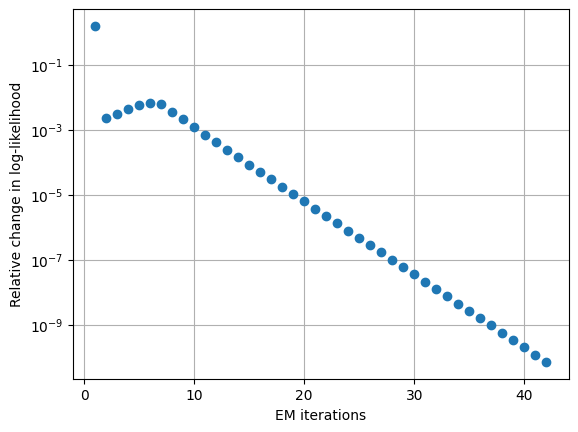

In [32]:
delta_rel = np.abs(np.diff(EM_ll)) / np.maximum(np.abs(EM_ll[:-1]), np.abs(EM_ll[1:]), np.ones(len(EM_ll)-1))
plt.semilogy(range(1,len(EM_ll)), delta_rel, 'o')
plt.xlabel('EM iterations')
plt.ylabel('Relative change in log-likelihood')
plt.grid()
plt.show()

## Validation

### Temporal predictions at fixed locations

In [33]:
Mu_L, Var_L = np.zeros((N_test, 5)), np.zeros((N_test, 5))
Mu_H, Var_H = np.zeros((N_test, 5)), np.zeros((N_test, 5))
for i in range(5):
    positions = st_positions[i]
    X_test = np.column_stack((positions[0]*np.ones(N_test), positions[1]*np.ones(N_test), time_test))
    norm_X_test = Normalize(X_test, minXL, maxXL, mXL)
    mu_L, cov_L, mu_H, cov_H = MF_gp.prediction(norm_X_test, only_diag_cov=True)
    Mu_L[:,i] = deNormalize(mu_L, minzL, maxzL, mzL).ravel()
    Var_L[:,i] = cov_L.ravel() * cov_correction
    Mu_H[:,i] = deNormalize(mu_H, minzL, maxzL, mzL).ravel()
    Var_H[:,i] = cov_H.ravel() * cov_correction

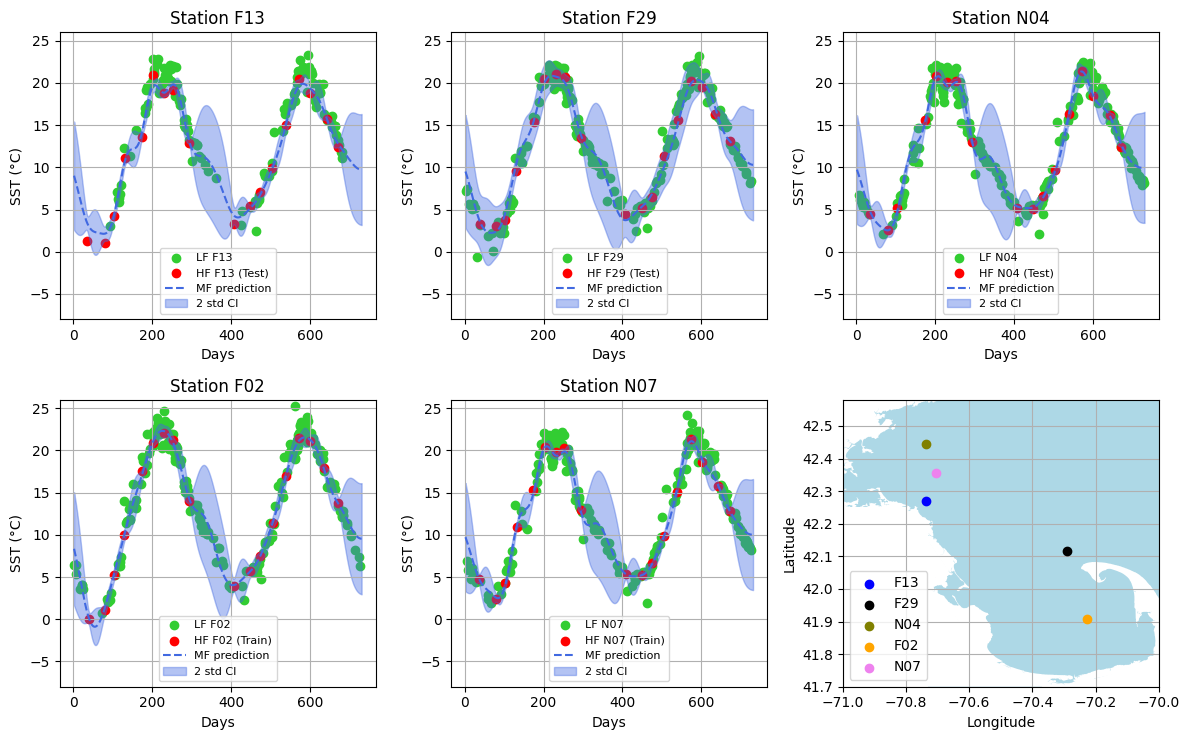

In [34]:
train_and_test = [' (Test)', ' (Test)', ' (Test)', ' (Train)', ' (Train)']

fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
axes = axes.ravel() 
for ax in axes[1:5]:
    ax.sharex(axes[0])
    ax.sharey(axes[0])
for i in range(5):
    ax = axes[i]
    name = stations[i]
    path_LF = f"../data/data_cape_cod/Stat_{name}_LF.txt"
    LF_data = np.loadtxt(path_LF)
    X_Lsta, z_Lsta = LF_data[:,0], LF_data[:,1]
    path_HF = f"../data/data_cape_cod/Stat_{name}_HF.txt"
    HF_data = np.loadtxt(path_HF)
    X_Hsta, z_Hsta = HF_data[:,0], HF_data[:,1]
    ax.scatter(X_Lsta, z_Lsta, color='limegreen',label=f'LF {name}')
    ax.scatter(X_Hsta, z_Hsta, color='red',label=f'HF {name}'+train_and_test[i])
    ax.plot(time_test, Mu_H[:,i], color='royalblue', label="MF prediction", linestyle='--')
    ax.fill_between(time_test.ravel(),
                 Mu_H[:,i] - 2. * np.sqrt(Var_H[:,i]),
                 Mu_H[:,i] + 2. * np.sqrt(Var_H[:,i]),
                 alpha=0.4, color='royalblue', label="2 std CI")
    # ax.fill_between(time_test.ravel(),
    #              Mu_H[:,i] - 2. * np.sqrt(Var_H[:,i]+nv_mf),
    #              Mu_H[:,i] + 2. * np.sqrt(Var_H[:,i]+nv_mf),
    #              alpha=0.4, color='orange', label="2 std PI")
    ax.set_xlabel('Days')
    ax.set_ylabel('SST (°C)')
    ax.legend(fontsize=8, loc='lower center')
    ax.set_title(f'Station {name}')
    ax.grid()
    ax.set_ylim(-8, 26)
ax = axes[5]
for i in range(5):
    name = stations[i]
    plot_bays(ax, geom_code, geom_mass)
    ax.scatter(st_positions[i,0], st_positions[i,1], color=colors[i],label=f'{name}', zorder=5)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.legend(loc='lower left')
    ax.set_xlim(-71, -70)
    ax.set_ylim(41.7, 42.58)
    ax.grid(True)
plt.tight_layout()
#plt.savefig(plot_dir+"/CapeCod_MF_time_results.pdf", format="pdf")
plt.show()

### Spatial predictions for a specific time

#### March 22, 2015

In [35]:
num_loc = 100
longitudes = np.linspace(-71.0, -70.0, num_loc)
latitudes = np.linspace(41.7, 42.6, num_loc)
locX, locY = np.meshgrid(longitudes, latitudes)
locations = np.column_stack([locX.ravel(), locY.ravel()])
locations.shape

(10000, 2)

In [36]:
stations = ["F01", "F02", "F06", "F10", "F15", "F22", "F23", "N01", "N07", "N18", "N21"]
# Positions of the stations (those used in the training set) for spatial predictions (longitude, latitude)
st_positions = np.array([[-7.0453333e+01, 4.1850833e+01], 
                         [-7.0228333e+01, 4.1908167e+01],
                         [-7.0576667e+01, 4.2170667e+01],
                         [-7.0637333e+01, 4.2242333e+01],
                         [-7.0727667e+01, 4.2315500e+01],
                         [-7.0617667e+01, 4.2479833e+01],
                         [-7.0942000e+01, 4.2339167e+01],
                         [-7.0864500e+01, 4.2419333e+01],
                         [-7.0706167e+01, 4.2356333e+01],
                         [-7.0777667e+01, 4.2365833e+01],
                         [-7.0785333e+01, 4.2387833e+01]])

In [37]:
day = 82.  # corresponds to March 22, 2015.
X_test = np.concatenate((locations, day*np.ones((locations.shape[0], 1))), axis=1)  # first day corresponds to time=2.
X_test.shape

(10000, 3)

In [38]:
norm_X_test = Normalize(X_test, minXL, maxXL, mXL)
mu_L, cov_L, mu_H, cov_H = MF_gp.prediction(norm_X_test, only_diag_cov=True)
mu_L = deNormalize(mu_L, minzL, maxzL, mzL)
mu_H = deNormalize(mu_H, minzL, maxzL, mzL)
cov_L = cov_L * cov_correction
cov_H = cov_H * cov_correction
std_L = np.sqrt(cov_L)
std_H = np.sqrt(cov_H)

In [39]:
Mu_H = mu_H.reshape(locY.shape)
Sd_H = std_H.reshape(locY.shape)
Mu_L = mu_L.reshape(locY.shape)
Sd_L = std_L.reshape(locY.shape)

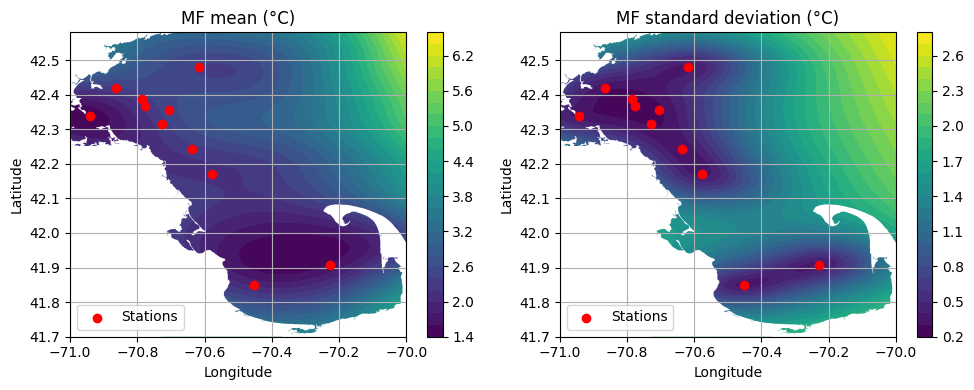

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
cont_f = ax.contourf(locX, locY, Mu_H, levels=30, cmap='viridis')
plot_bays(ax, geom_code, geom_mass, sea_color='none')   # sea color is none so it does not cover the relevant part of the plot
plt.colorbar(cont_f, ax=ax)
ax.scatter(st_positions[:,0], st_positions[:,1], color='red', zorder=5, label='Stations')
ax.set_title('MF mean (°C)')
ax.set_xlim(-71, -70)
ax.set_ylim(41.7, 42.58)
ax.grid(True)
ax.legend(loc='lower left')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

ax = axes[1]
cont_g = ax.contourf(locX, locY, Sd_H, levels=30, cmap='viridis')
plot_bays(ax, geom_code, geom_mass, sea_color='none')
plt.colorbar(cont_g, ax=ax)
ax.scatter(st_positions[:,0], st_positions[:,1], color='red', zorder=5, label='Stations')
ax.set_title('MF standard deviation (°C)')
ax.set_xlim(-71, -70)
ax.set_ylim(41.7, 42.58)
ax.grid(True)
ax.legend(loc='lower left')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.tight_layout()
#plt.savefig(plot_dir+"/CapeCod_MF_space_results.pdf", format="pdf")
plt.show()

#### Other days

In [41]:
days_number = [2., 32., 62., 92., 122.]
name_days = ["January 1st, 2015", "January 31st, 2015", "March 2nd, 2015", "April 1st, 2015", "May 1st, 2015"]

Results for: January 1st, 2015


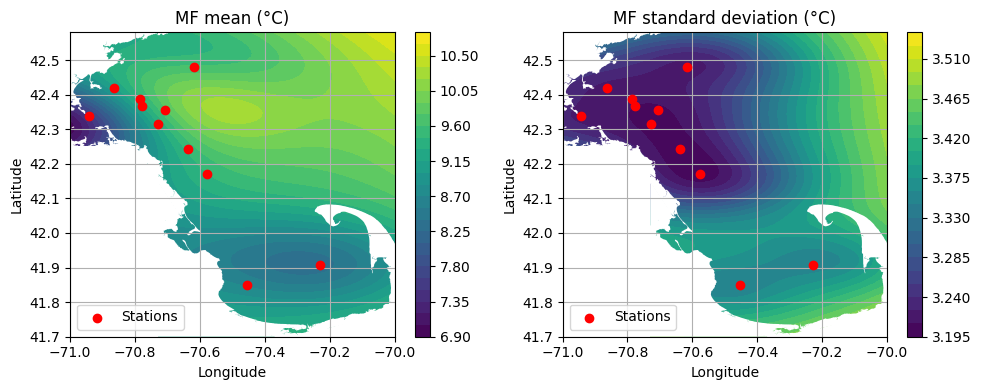

Results for: January 31st, 2015


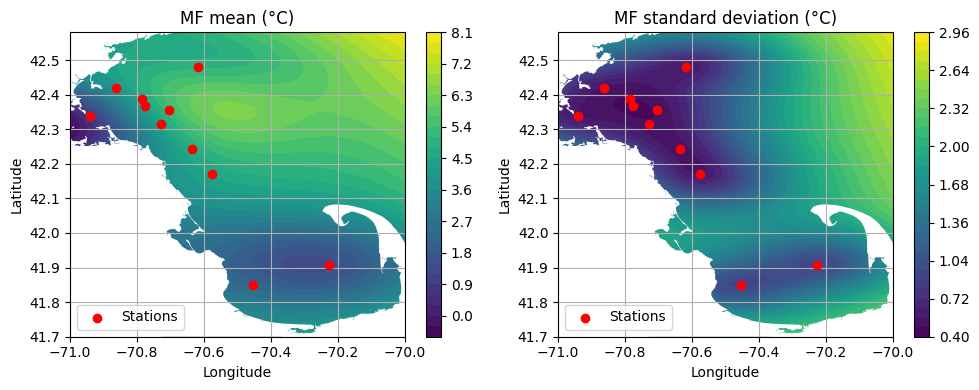

Results for: March 2nd, 2015


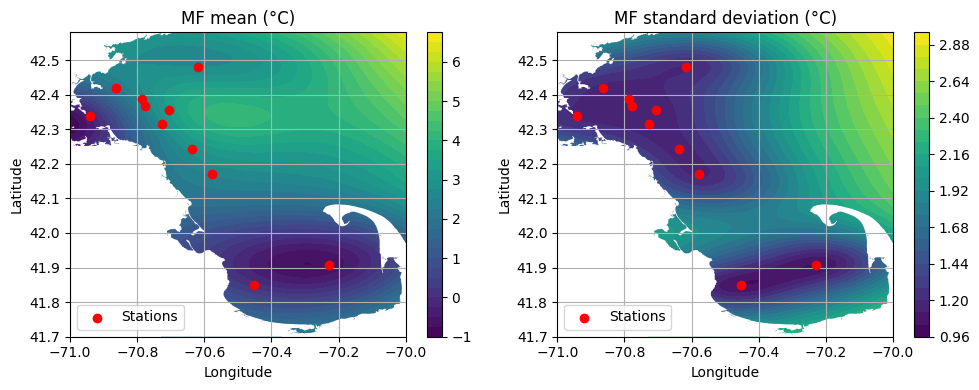

Results for: April 1st, 2015


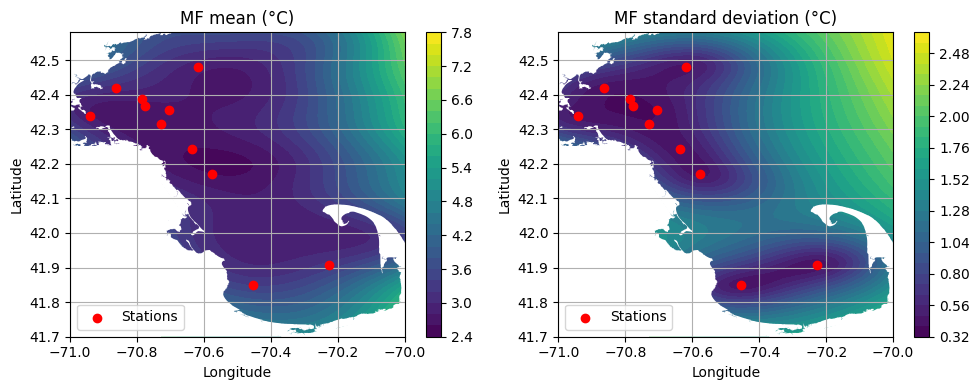

Results for: May 1st, 2015


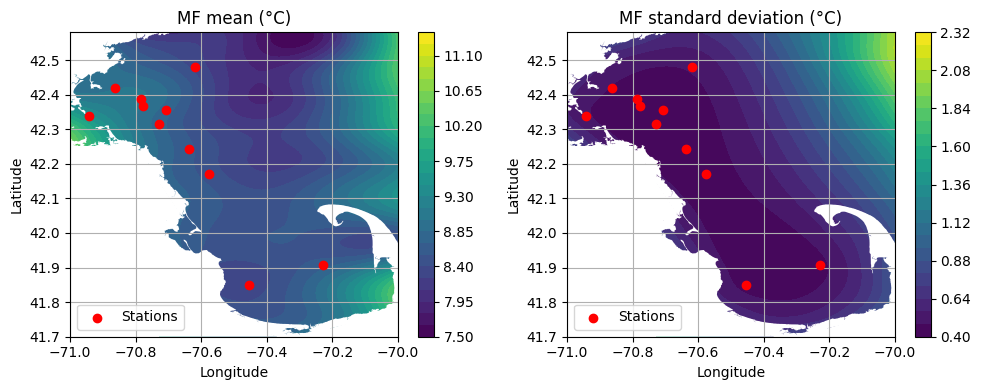

In [42]:
for i in range(len(days_number)):
    day = days_number[i]
    print("Results for: "+name_days[i])
    X_test = np.concatenate((locations, day*np.ones((locations.shape[0], 1))), axis=1)  
    norm_X_test = Normalize(X_test, minXL, maxXL, mXL)
    mu_L, cov_L, mu_H, cov_H = MF_gp.prediction(norm_X_test, only_diag_cov=True)
    mu_L = deNormalize(mu_L, minzL, maxzL, mzL)
    mu_H = deNormalize(mu_H, minzL, maxzL, mzL)
    cov_L = cov_L * cov_correction
    cov_H = cov_H * cov_correction
    std_L = np.sqrt(cov_L)
    std_H = np.sqrt(cov_H)

    Mu_H = mu_H.reshape(locY.shape)
    Sd_H = std_H.reshape(locY.shape)
    Mu_L = mu_L.reshape(locY.shape)
    Sd_L = std_L.reshape(locY.shape)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    ax = axes[0]
    cont_f = ax.contourf(locX, locY, Mu_H, levels=30, cmap='viridis')
    plot_bays(ax, geom_code, geom_mass, sea_color='none')   # sea color is none so it does not cover the relevant part of the plot
    plt.colorbar(cont_f, ax=ax)
    ax.scatter(st_positions[:,0], st_positions[:,1], color='red', zorder=5, label='Stations')
    ax.set_title('MF mean (°C)')
    ax.set_xlim(-71, -70)
    ax.set_ylim(41.7, 42.58)
    ax.grid(True)
    ax.legend(loc='lower left')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')

    ax = axes[1]
    cont_g = ax.contourf(locX, locY, Sd_H, levels=30, cmap='viridis')
    plot_bays(ax, geom_code, geom_mass, sea_color='none')
    plt.colorbar(cont_g, ax=ax)
    ax.scatter(st_positions[:,0], st_positions[:,1], color='red', zorder=5, label='Stations')
    ax.set_title('MF standard deviation (°C)')
    ax.set_xlim(-71, -70)
    ax.set_ylim(41.7, 42.58)
    ax.grid(True)
    ax.legend(loc='lower left')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    plt.tight_layout()
    plt.show()

## Non-recursive optimization

### Train

In [43]:
want_to_retrain = False     # if True, re-train the model, if False, loads the saved model.
want_to_save = False      # if True, save the re-trained model.
seed = 0
np.random.seed(seed)
verbose = True

In [44]:
theta_L = (np.max(norm_X_L, axis=0) - np.min(norm_X_L, axis=0)) / 2
mbasis_L = Constant_basis(None)
sigma2_L = 1.
kernel_L = RBF_kernel(theta_L, sigma2_L) 
zeta_L = np.array([0.])
eta_fnL = Homoscedastic(params=zeta_L)
gp_L = GPR(mbasis_L, kernel_L, norm_X_L, norm_z_L, noise='opt', eta_fn=eta_fnL)
theta_H =  (np.max(norm_X_H, axis=0) - np.min(norm_X_H, axis=0)) / 2
beta_H = np.array([[0.]])
beta_rho = np.array([[1.]])
sigma2_H = 1.
mbasis_H = Constant_basis(beta_H) 
scale = Constant_basis(beta_rho)
kernel_H = RBF_kernel(theta_H, sigma2_H)
zeta_H = np.array([0.])
eta_fnH = Homoscedastic(params=zeta_H)
gp_H = GPR(mbasis_H, kernel_H, norm_X_H, norm_z_H, noise='opt', eta_fn=eta_fnH)
MF_gpKO = Multifi_GP_AR1_KO(gp_L, gp_H, scale)
MF_gpKO.bounds[-1] = (-10., 10.)

In [45]:
n_starts = 10
n_cores = 1
namefile = os.path.join(data_dir, "capecod_MF-GP-KO_model.pkl")
nametime = os.path.join(data_dir, "capecod_MF-GP-KO_time.pkl")
if want_to_retrain:
    t1_ko = time.time()
    best, nlml_value = MF_gpKO.fit(n_starts=n_starts, n_cores=n_cores, jitter=1e-6, rng_seed=seed, verbose=verbose)
    t2_ko = time.time()
    t_ko = t2_ko - t1_ko 
    if want_to_save:
        with open(namefile, "wb") as f:
            pickle.dump(MF_gpKO, f)
        with open(nametime, "wb") as f:
            pickle.dump(t_ko, f)
else:
    with open(namefile, "rb") as f:
        MF_gpKO = pickle.load(f)
    with open(nametime, "rb") as f:
        t_ko = pickle.load(f)
print(MF_gpKO)

Parameter Name      Value               
----------------------------------------
LF_mean_params      [[-0.04371357]]     
LF_kernel_variance  0.02241452305769485 
LF_length_scale     [0.26815398 0.10785578 0.04958678]
LF_noise_variance   6.692181694076585e-05
scaling_params      [[0.46744399]]      
HF_mean_params      [[-0.04329629]]     
HF_kernel_variance  0.019339136943954206
HF_length_scale     [0.713667   0.7124245  0.04350095]
HF_noise_variance   0.0002687666683461598


In [46]:
print(t_ko)

4880.6348333358765


In [47]:
print(f'Training time ratio: {t_ko / (t_lf + t_mf)}')

Training time ratio: 5.414358480267669


### Temporal predictions

In [48]:
stations = ['F13', 'F29', 'N04', 'F02', 'N07']
st_positions = np.array([[-7.0735000e+01, 4.2268333e+01], 
                         [-7.0290000e+01, 4.2116667e+01],
                         [-7.0736500e+01, 4.2443833e+01],
                         [-7.0228333e+01, 4.1908167e+01],
                         [-7.0706167e+01, 4.2356333e+01]])

In [49]:
Mu_H, Var_H = np.zeros((N_test, 5)), np.zeros((N_test, 5))
for i in range(5):
    positions = st_positions[i]
    X_test = np.column_stack((positions[0]*np.ones(N_test), positions[1]*np.ones(N_test), time_test))
    norm_X_test = Normalize(X_test, minXL, maxXL, mXL)
    mu_H, cov_H = MF_gpKO.prediction(norm_X_test, only_diag_cov=True)
    Mu_H[:,i] = deNormalize(mu_H, minzL, maxzL, mzL).ravel()
    Var_H[:,i] = cov_H.ravel() * cov_correction

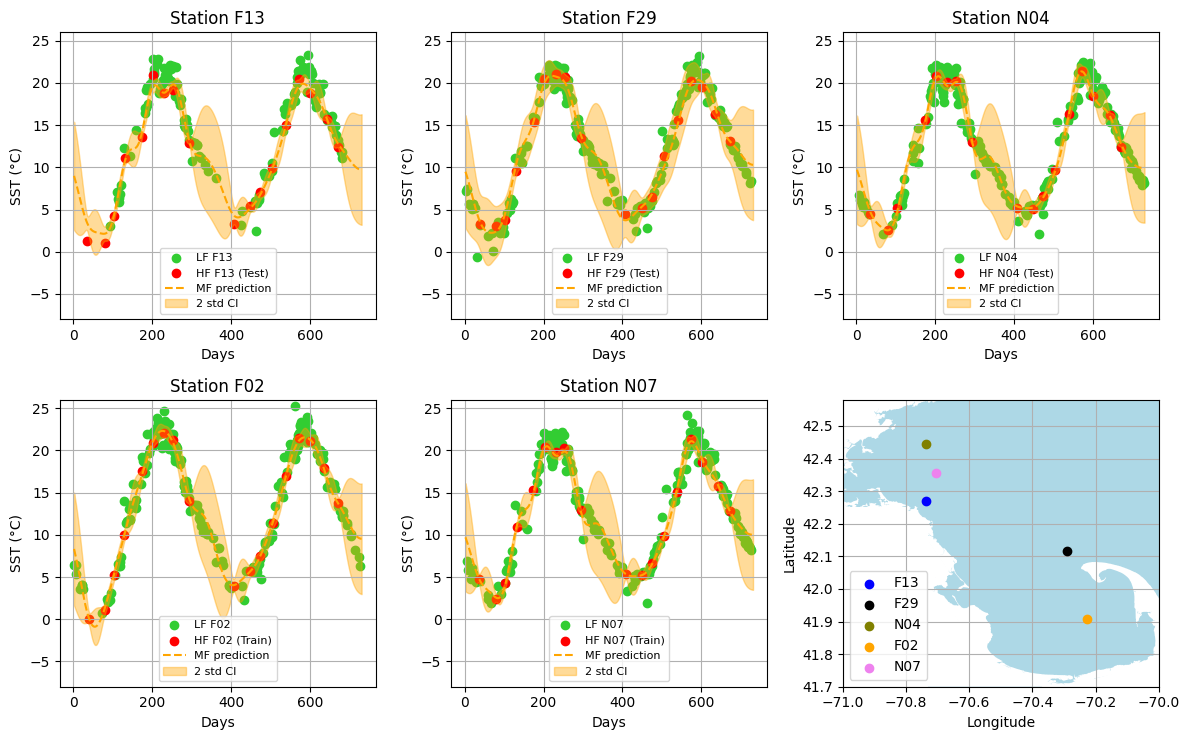

In [50]:
train_and_test = [' (Test)', ' (Test)', ' (Test)', ' (Train)', ' (Train)']
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
axes = axes.ravel() 
for ax in axes[1:5]:
    ax.sharex(axes[0])
    ax.sharey(axes[0])
for i in range(5):
    ax = axes[i]
    name = stations[i]
    path_LF = f"../data/data_cape_cod/Stat_{name}_LF.txt"
    LF_data = np.loadtxt(path_LF)
    X_Lsta, z_Lsta = LF_data[:,0], LF_data[:,1]
    path_HF = f"../data/data_cape_cod/Stat_{name}_HF.txt"
    HF_data = np.loadtxt(path_HF)
    X_Hsta, z_Hsta = HF_data[:,0], HF_data[:,1]
    ax.scatter(X_Lsta, z_Lsta, color='limegreen',label=f'LF {name}')
    ax.scatter(X_Hsta, z_Hsta, color='red',label=f'HF {name}'+train_and_test[i])
    ax.plot(time_test, Mu_H[:,i], color='orange', label="MF prediction", linestyle='--')
    ax.fill_between(time_test.ravel(),
                 Mu_H[:,i] - 2. * np.sqrt(Var_H[:,i]),
                 Mu_H[:,i] + 2. * np.sqrt(Var_H[:,i]),
                 alpha=0.4, color='orange', label="2 std CI")
    # ax.fill_between(time_test.ravel(),
    #              Mu_H[:,i] - 2. * np.sqrt(Var_H[:,i]+nv_mf),
    #              Mu_H[:,i] + 2. * np.sqrt(Var_H[:,i]+nv_mf),
    #              alpha=0.4, color='orange', label="2 std PI")
    ax.set_xlabel('Days')
    ax.set_ylabel('SST (°C)')
    ax.legend(fontsize=8, loc='lower center')
    ax.set_title(f'Station {name}')
    ax.grid()
    ax.set_ylim(-8, 26)
ax = axes[5]
for i in range(5):
    name = stations[i]
    plot_bays(ax, geom_code, geom_mass)
    ax.scatter(st_positions[i,0], st_positions[i,1], color=colors[i],label=f'{name}', zorder=5)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.legend(loc='lower left')
    ax.set_xlim(-71, -70)
    ax.set_ylim(41.7, 42.58)
    ax.grid(True)
plt.tight_layout()
#plt.savefig(plot_dir+"/CapeCod_MFKO_time_results.pdf", format="pdf")
plt.show()

### Spatial predictions

In [51]:
num_loc = 100
longitudes = np.linspace(-71.0, -70.0, num_loc)
latitudes = np.linspace(41.7, 42.6, num_loc)
locX, locY = np.meshgrid(longitudes, latitudes)
locations = np.column_stack([locX.ravel(), locY.ravel()])
locations.shape

(10000, 2)

In [52]:
stations = ["F01", "F02", "F06", "F10", "F15", "F22", "F23", "N01", "N07", "N18", "N21"]
# Positions of the stations (those used in the training set) for spatial predictions (longitude, latitude)
st_positions = np.array([[-7.0453333e+01, 4.1850833e+01], 
                         [-7.0228333e+01, 4.1908167e+01],
                         [-7.0576667e+01, 4.2170667e+01],
                         [-7.0637333e+01, 4.2242333e+01],
                         [-7.0727667e+01, 4.2315500e+01],
                         [-7.0617667e+01, 4.2479833e+01],
                         [-7.0942000e+01, 4.2339167e+01],
                         [-7.0864500e+01, 4.2419333e+01],
                         [-7.0706167e+01, 4.2356333e+01],
                         [-7.0777667e+01, 4.2365833e+01],
                         [-7.0785333e+01, 4.2387833e+01]])

In [53]:
day = 82.  # corresponds to March 22, 2015.
X_test = np.concatenate((locations, day*np.ones((locations.shape[0], 1))), axis=1)  # first day corresponds to time=2.
X_test.shape

(10000, 3)

In [54]:
norm_X_test = Normalize(X_test, minXL, maxXL, mXL)
mu_H, cov_H = MF_gpKO.prediction(norm_X_test, only_diag_cov=True)
mu_H = deNormalize(mu_H, minzL, maxzL, mzL)
cov_H = cov_H * cov_correction
std_H = np.sqrt(cov_H)

In [55]:
Mu_H = mu_H.reshape(locY.shape)
Sd_H = std_H.reshape(locY.shape)

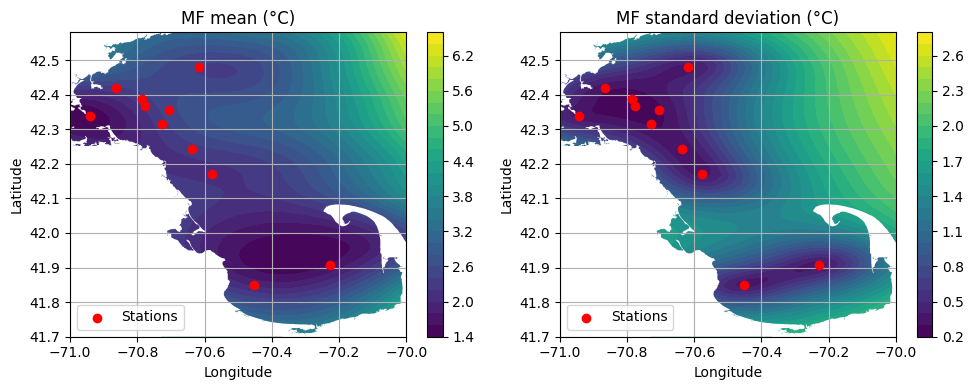

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
cont_f = ax.contourf(locX, locY, Mu_H, levels=30, cmap='viridis')
plot_bays(ax, geom_code, geom_mass, sea_color='none')   # sea color is none so it does not cover the relevant part of the plot
plt.colorbar(cont_f, ax=ax)
ax.scatter(st_positions[:,0], st_positions[:,1], color='red', zorder=5, label='Stations')
ax.set_title('MF mean (°C)')
ax.set_xlim(-71, -70)
ax.set_ylim(41.7, 42.58)
ax.grid(True)
ax.legend(loc='lower left')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

ax = axes[1]
cont_g = ax.contourf(locX, locY, Sd_H, levels=30, cmap='viridis')
plot_bays(ax, geom_code, geom_mass, sea_color='none')
plt.colorbar(cont_g, ax=ax)
ax.scatter(st_positions[:,0], st_positions[:,1], color='red', zorder=5, label='Stations')
ax.set_title('MF standard deviation (°C)')
ax.set_xlim(-71, -70)
ax.set_ylim(41.7, 42.58)
ax.grid(True)
ax.legend(loc='lower left')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.tight_layout()
#plt.savefig(plot_dir+"/CapeCod_MFKO_space_results.pdf", format="pdf")
plt.show()

## Recursive vs Non-recursive plots

In [57]:
print(MF_gp)

Parameter Name      Value               
----------------------------------------
LF_mean_params      [[-0.04186298]]     
LF_kernel_variance  [0.022146]          
LF_length_scale     [0.26854746 0.10691291 0.04958678]
LF_eta_fn_params    [-5.79334719]       
LF_noise_variance   [6.74957664e-05]    
scaling_params      [[0.46580404]]      
HF_mean_params      [[-0.04361331]]     
HF_kernel_variance  [0.01952563]        
HF_length_scale     [0.713667   0.71885714 0.04350833]
HF_eta_fn_params    [-4.27779518]       
HF_noise_variance   [0.00027088]        


In [58]:
print(MF_gpKO)

Parameter Name      Value               
----------------------------------------
LF_mean_params      [[-0.04371357]]     
LF_kernel_variance  0.02241452305769485 
LF_length_scale     [0.26815398 0.10785578 0.04958678]
LF_noise_variance   6.692181694076585e-05
scaling_params      [[0.46744399]]      
HF_mean_params      [[-0.04329629]]     
HF_kernel_variance  0.019339136943954206
HF_length_scale     [0.713667   0.7124245  0.04350095]
HF_noise_variance   0.0002687666683461598


In [59]:
stations = ['F13', 'F29', 'N04', 'F02', 'N07']
st_positions = np.array([[-7.0735000e+01, 4.2268333e+01], 
                         [-7.0290000e+01, 4.2116667e+01],
                         [-7.0736500e+01, 4.2443833e+01],
                         [-7.0228333e+01, 4.1908167e+01],
                         [-7.0706167e+01, 4.2356333e+01]])

In [60]:
Mu_L, Var_L = np.zeros((N_test, 5)), np.zeros((N_test, 5))
Mu_H, Var_H = np.zeros((N_test, 5)), np.zeros((N_test, 5))
for i in range(5):
    positions = st_positions[i]
    X_test = np.column_stack((positions[0]*np.ones(N_test), positions[1]*np.ones(N_test), time_test))
    norm_X_test = Normalize(X_test, minXL, maxXL, mXL)
    mu_L, cov_L, mu_H, cov_H = MF_gp.prediction(norm_X_test, only_diag_cov=True)
    Mu_L[:,i] = deNormalize(mu_L, minzL, maxzL, mzL).ravel()
    Var_L[:,i] = cov_L.ravel() * cov_correction
    Mu_H[:,i] = deNormalize(mu_H, minzL, maxzL, mzL).ravel()
    Var_H[:,i] = cov_H.ravel() * cov_correction

In [61]:
Mu_Hko, Var_Hko = np.zeros((N_test, 5)), np.zeros((N_test, 5))
for i in range(5):
    positions = st_positions[i]
    X_test = np.column_stack((positions[0]*np.ones(N_test), positions[1]*np.ones(N_test), time_test))
    norm_X_test = Normalize(X_test, minXL, maxXL, mXL)
    mu_H, cov_H = MF_gpKO.prediction(norm_X_test, only_diag_cov=True)
    Mu_Hko[:,i] = deNormalize(mu_H, minzL, maxzL, mzL).ravel()
    Var_Hko[:,i] = cov_H.ravel() * cov_correction

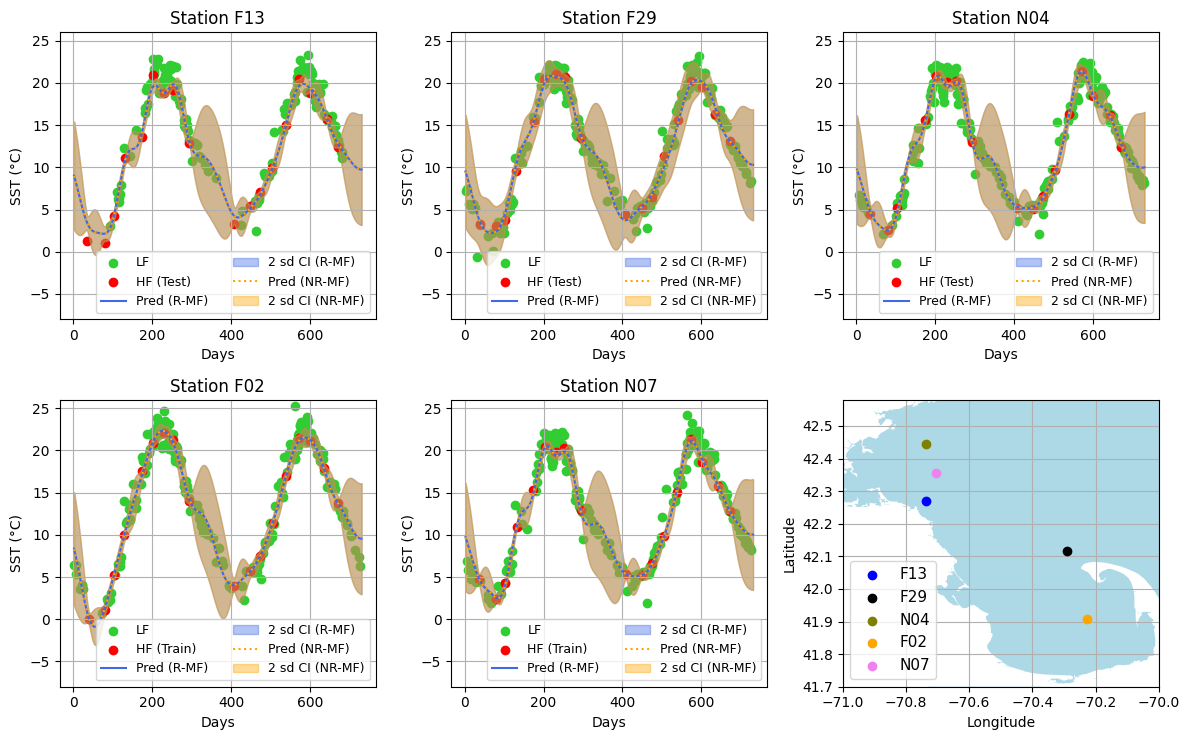

In [62]:
train_and_test = [' (Test)', ' (Test)', ' (Test)', ' (Train)', ' (Train)']
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
axes = axes.ravel() 
for ax in axes[1:5]:
    ax.sharex(axes[0])
    ax.sharey(axes[0])
for i in range(5):
    ax = axes[i]
    name = stations[i]
    path_LF = f"../data/data_cape_cod/Stat_{name}_LF.txt"
    LF_data = np.loadtxt(path_LF)
    X_Lsta, z_Lsta = LF_data[:,0], LF_data[:,1]
    path_HF = f"../data/data_cape_cod/Stat_{name}_HF.txt"
    HF_data = np.loadtxt(path_HF)
    X_Hsta, z_Hsta = HF_data[:,0], HF_data[:,1]
    # ax.scatter(X_Lsta, z_Lsta, color='limegreen',label=f'LF {name}')
    # ax.scatter(X_Hsta, z_Hsta, color='red',label=f'HF {name}'+train_and_test[i])
    ax.scatter(X_Lsta, z_Lsta, color='limegreen',label=f'LF')
    ax.scatter(X_Hsta, z_Hsta, color='red',label=f'HF'+train_and_test[i])
    ax.plot(time_test, Mu_H[:,i], color='royalblue', label="Pred (R-MF)")
    ax.fill_between(time_test.ravel(),
                 Mu_H[:,i] - 2. * np.sqrt(Var_H[:,i]),
                 Mu_H[:,i] + 2. * np.sqrt(Var_H[:,i]),
                 alpha=0.4, color='royalblue', label="2 sd CI (R-MF)")
    ax.plot(time_test, Mu_Hko[:,i], color='orange', label="Pred (NR-MF)", linestyle='dotted')
    ax.fill_between(time_test.ravel(),
                 Mu_Hko[:,i] - 2. * np.sqrt(Var_Hko[:,i]),
                 Mu_Hko[:,i] + 2. * np.sqrt(Var_Hko[:,i]),
                 alpha=0.4, color='orange', label="2 sd CI (NR-MF)")
    # ax.fill_between(time_test.ravel(),
    #              Mu_H[:,i] - 2. * np.sqrt(Var_H[:,i]+nv_mf),
    #              Mu_H[:,i] + 2. * np.sqrt(Var_H[:,i]+nv_mf),
    #              alpha=0.4, color='orange', label="2 std PI")
    ax.set_xlabel('Days')
    ax.set_ylabel('SST (°C)')
    ax.legend(fontsize=9, loc='lower right', ncol=2)
    #ax.legend(fontsize=7, loc='lower right')
    ax.set_title(f'Station {name}')
    ax.grid()
    ax.set_ylim(-8, 26)
ax = axes[5]
for i in range(5):
    name = stations[i]
    plot_bays(ax, geom_code, geom_mass)
    ax.scatter(st_positions[i,0], st_positions[i,1], color=colors[i],label=f'{name}', zorder=5)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.legend(loc='lower left', fontsize=11)
    ax.set_xlim(-71, -70)
    ax.set_ylim(41.7, 42.58)
    ax.grid(True)
plt.tight_layout()
plt.savefig(plot_dir+"/CapeCod_MF_Rec+KO_time_results.pdf", format="pdf")

In [63]:
num_loc = 100
longitudes = np.linspace(-71.0, -70.0, num_loc)
latitudes = np.linspace(41.7, 42.6, num_loc)
locX, locY = np.meshgrid(longitudes, latitudes)
locations = np.column_stack([locX.ravel(), locY.ravel()])
locations.shape

(10000, 2)

In [64]:
stations = ["F01", "F02", "F06", "F10", "F15", "F22", "F23", "N01", "N07", "N18", "N21"]
# Positions of the stations (those used in the training set) for spatial predictions (longitude, latitude)
st_positions = np.array([[-7.0453333e+01, 4.1850833e+01], 
                         [-7.0228333e+01, 4.1908167e+01],
                         [-7.0576667e+01, 4.2170667e+01],
                         [-7.0637333e+01, 4.2242333e+01],
                         [-7.0727667e+01, 4.2315500e+01],
                         [-7.0617667e+01, 4.2479833e+01],
                         [-7.0942000e+01, 4.2339167e+01],
                         [-7.0864500e+01, 4.2419333e+01],
                         [-7.0706167e+01, 4.2356333e+01],
                         [-7.0777667e+01, 4.2365833e+01],
                         [-7.0785333e+01, 4.2387833e+01]])

In [65]:
day = 82.  # corresponds to March 22, 2015.
X_test = np.concatenate((locations, day*np.ones((locations.shape[0], 1))), axis=1)  # first day corresponds to time=2.
norm_X_test = Normalize(X_test, minXL, maxXL, mXL)

In [66]:
mu_L, cov_L, mu_H, cov_H = MF_gp.prediction(norm_X_test, only_diag_cov=True)
mu_L = deNormalize(mu_L, minzL, maxzL, mzL)
mu_H = deNormalize(mu_H, minzL, maxzL, mzL)
cov_L = cov_L * cov_correction
cov_H = cov_H * cov_correction
std_L = np.sqrt(cov_L)
std_H = np.sqrt(cov_H)

In [67]:
mu_Hko, cov_Hko = MF_gpKO.prediction(norm_X_test, only_diag_cov=True)
mu_Hko = deNormalize(mu_Hko, minzL, maxzL, mzL)
cov_Hko = cov_Hko * cov_correction
std_Hko = np.sqrt(cov_Hko)

In [68]:
Mu_H = mu_H.reshape(locY.shape)
Sd_H = std_H.reshape(locY.shape)
Mu_L = mu_L.reshape(locY.shape)
Sd_L = std_L.reshape(locY.shape)
Mu_Hko = mu_Hko.reshape(locY.shape)
Sd_Hko = std_Hko.reshape(locY.shape)

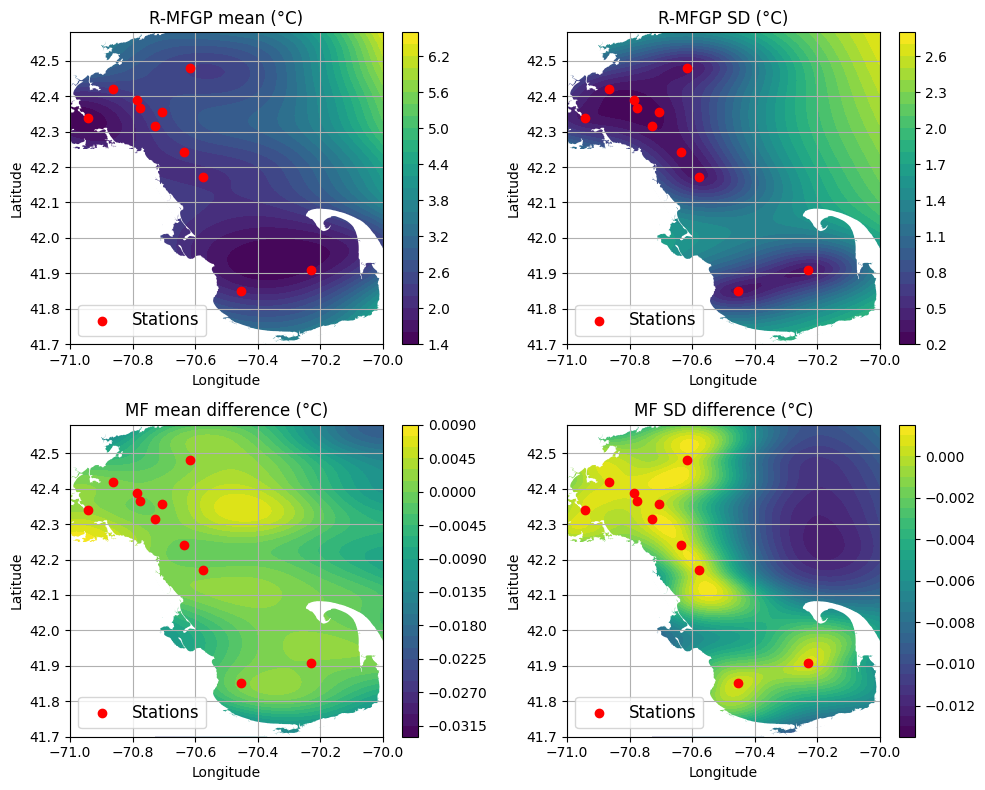

In [69]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
ax = axes[0, 0]
cont = ax.contourf(locX, locY, Mu_H, levels=30, cmap='viridis')
plot_bays(ax, geom_code, geom_mass, sea_color='none')
plt.colorbar(cont, ax=ax)
ax.scatter(st_positions[:,0], st_positions[:,1], color='red', zorder=5, label='Stations')
ax.set_title('R-MFGP mean (°C)')
ax.set_xlim(-71, -70)
ax.set_ylim(41.7, 42.58)
ax.grid(True)
ax.legend(loc='lower left', fontsize=12.)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

ax = axes[0, 1]
cont = ax.contourf(locX, locY, Sd_H, levels=30, cmap='viridis')
plot_bays(ax, geom_code, geom_mass, sea_color='none')
plt.colorbar(cont, ax=ax)
ax.scatter(st_positions[:,0], st_positions[:,1], color='red', zorder=5, label='Stations')
ax.set_title('R-MFGP SD (°C)')
ax.set_xlim(-71, -70)
ax.set_ylim(41.7, 42.58)
ax.grid(True)
ax.legend(loc='lower left', fontsize=12.)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

ax = axes[1, 0]
cont = ax.contourf(locX, locY, Mu_H - Mu_Hko, levels=30, cmap='viridis')
plot_bays(ax, geom_code, geom_mass, sea_color='none')
plt.colorbar(cont, ax=ax)
ax.scatter(st_positions[:,0], st_positions[:,1], color='red', zorder=5, label='Stations')
ax.set_title('MF mean difference (°C)')
ax.set_xlim(-71, -70)
ax.set_ylim(41.7, 42.58)
ax.grid(True)
ax.legend(loc='lower left', fontsize=12.)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

ax = axes[1, 1]
cont = ax.contourf(locX, locY, Sd_H - Sd_Hko, levels=30, cmap='viridis')
plot_bays(ax, geom_code, geom_mass, sea_color='none')
plt.colorbar(cont, ax=ax)
ax.scatter(st_positions[:,0], st_positions[:,1], color='red', zorder=5, label='Stations')
ax.set_title('MF SD difference (°C)')
ax.set_xlim(-71, -70)
ax.set_ylim(41.7, 42.58)
ax.grid(True)
ax.legend(loc='lower left', fontsize=12.)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

plt.tight_layout()
plt.savefig(plot_dir + "/CapeCod_MF_Rec+Diff_space_results.pdf",format="pdf")
plt.show()

## Test metrics

In [70]:
# HF-only-GP
seed = 0
np.random.seed(seed)
verbose = True
theta_Hsk =  (np.max(norm_X_H, axis=0) - np.min(norm_X_H, axis=0)) / 2
beta_Hsk = np.array([[0.]])
sigma2_Hsk = 1.
mbasis_Hsk = Constant_basis(beta_Hsk) 
kernel_Hsk = RBF_kernel(theta_Hsk, sigma2_Hsk)
zeta_Hsk = np.array([0.])
eta_fnHsk = Homoscedastic(params=zeta_Hsk)
gp_Hsk = GPR(mbasis_Hsk, kernel_Hsk, norm_X_H, norm_z_H, noise='opt', eta_fn=eta_fnHsk)

In [71]:
n_starts = 10
n_cores = 1
# ~ 2-3 s
best, nlml_value = gp_Hsk.fit(n_starts=n_starts, n_cores=n_cores, jitter=1e-10, rng_seed=seed, verbose=verbose)

Sequential optimization
Start 0: fun_value=-336.8148, nb_fun_eval=22, nb_grad_eval=22
Start 1: fun_value=-336.8148, nb_fun_eval=51, nb_grad_eval=51
Start 2: fun_value=-336.8148, nb_fun_eval=41, nb_grad_eval=41
Start 3: fun_value=-219.7915, nb_fun_eval=27, nb_grad_eval=27
Start 4: fun_value=45.3169, nb_fun_eval=14, nb_grad_eval=14
Start 5: fun_value=-336.8148, nb_fun_eval=28, nb_grad_eval=28
Start 6: fun_value=-336.8148, nb_fun_eval=28, nb_grad_eval=28
Start 7: fun_value=-336.8148, nb_fun_eval=38, nb_grad_eval=38
Start 8: fun_value=45.3207, nb_fun_eval=2, nb_grad_eval=2
Start 9: fun_value=-336.8148, nb_fun_eval=27, nb_grad_eval=27


In [72]:
print(gp_Hsk)

Parameter Name      Value               
----------------------------------------
mean_params         [[-0.10843692]]     
kernel_variance     [0.04649336]        
length_scale        [0.44147375 0.71885714 0.05441523]
eta_fn_params       [-5.04325666]       
noise_variance      [0.00030001]        


In [73]:
stations = ['F13', 'F29', 'N04']
st_positions = np.array([[-7.0735000e+01, 4.2268333e+01], 
                         [-7.0290000e+01, 4.2116667e+01],
                         [-7.0736500e+01, 4.2443833e+01]])
Mu_H, Var_H = [], []
Mu_Hko, Var_Hko = [], []
Mu_Hsk, Var_Hsk = [], []
st_temp = []

noise_Hsk = np.exp(gp_Hsk.eta_fn.zeta) * gp_Hsk.kernel.sigma2 * cov_correction
noise_H = np.exp(MF_gp.HF_GP.eta_fn.zeta) * MF_gp.HF_GP.kernel.sigma2 * cov_correction
noise_Hko = np.exp(MF_gpKO.HF_GP.eta_fn.zeta) * cov_correction

for i in range(3):
    st_name = stations[i]
    positions = st_positions[i]
    data_station = np.loadtxt(f"../data/data_cape_cod/Stat_{st_name}_HF.txt")
    st_num = data_station.shape[0]
    X_test = np.column_stack((positions[0]*np.ones(st_num), positions[1]*np.ones(st_num), data_station[:, 0]))
    norm_X_test = Normalize(X_test, minXL, maxXL, mXL)
    st_temp.append(data_station[:, 1])
    # HFGP
    mu_Hsk, cov_Hsk = gp_Hsk.prediction(norm_X_test, only_diag_cov=True)
    Mu_Hsk.append(deNormalize(mu_Hsk, minzL, maxzL, mzL).ravel())
    Var_Hsk.append(cov_Hsk.ravel() * cov_correction)
    # R-MFGP
    mu_L, cov_L, mu_H, cov_H = MF_gp.prediction(norm_X_test, only_diag_cov=True)
    Mu_H.append(deNormalize(mu_H, minzL, maxzL, mzL).ravel())
    Var_H.append(cov_H.ravel() * cov_correction)
    # NR-MFGP
    mu_Hko, cov_Hko = MF_gpKO.prediction(norm_X_test, only_diag_cov=True)
    Mu_Hko.append(deNormalize(mu_Hko, minzL, maxzL, mzL).ravel())
    Var_Hko.append(cov_Hko.ravel() * cov_correction)

In [74]:
def Qsquared_emp(y_obs, meta_mean):
    y, mu = np.ravel(y_obs), np.ravel(meta_mean)
    return 1 - np.mean((mu - y)**2) / np.var(y)

def IAE_PI_emp(y_obs, meta_mean, meta_var, meta_noise=0.0, alphas=np.arange(0.001, 1.0, 0.001)):
    y, mu = np.ravel(y_obs), np.ravel(meta_mean)
    std = np.sqrt(np.ravel(meta_var) + meta_noise)
    u = np.abs(y - mu) / std                    
    z = norm.ppf(0.5 + alphas / 2)            
    coverage = (u[None, :] <= z[:, None]).mean(axis=1)
    iae = np.trapz(np.abs(coverage - alphas), alphas)
    return iae, alphas, coverage

def PI_width(meta_var, meta_noise=0.0, level=0.95):
    std = np.sqrt(np.ravel(meta_var) + meta_noise)
    return 2 * norm.ppf(0.5 + level / 2) * np.mean(std)

In [75]:
models = {'HFGP': (Mu_Hsk, Var_Hsk, noise_Hsk),
          'R-MFGP': (Mu_H, Var_H, noise_H),
          'NR-MFGP': (Mu_Hko, Var_Hko, noise_Hko)}

def print_table(title, tab, rows, cols):
    print(title)
    print(f"{'':<10}" + "".join(f"{c:>10}" for c in cols))
    for r, line in zip(rows, tab):
        print(f"{r:<10}" + "".join(f"{v:>10.3f}" for v in line))
    print()

Q2_tab = np.zeros((len(models), len(stations)))
IAE_tab = np.zeros((len(models), len(stations)))
W_tab = np.zeros((len(models), len(stations)))

for m, (Mu, Var, noise) in enumerate(models.values()):
    for i in range(len(stations)):
        Q2_tab[m, i] = Qsquared_emp(st_temp[i], Mu[i])
        IAE_tab[m, i] = IAE_PI_emp(st_temp[i], Mu[i], Var[i], noise)[0]
        W_tab[m, i] = PI_width(Var[i], noise)

print_table("Q2", Q2_tab.T, stations, models.keys())
print_table("IAE PI", IAE_tab.T, stations, models.keys())
print_table("PIW 95%", W_tab.T, stations, models.keys())

Q2
                HFGP    R-MFGP   NR-MFGP
F13            0.982     0.986     0.987
F29            0.980     0.992     0.992
N04            0.998     0.999     0.999

IAE PI
                HFGP    R-MFGP   NR-MFGP
F13            0.084     0.063     0.064
F29            0.081     0.122     0.123
N04            0.158     0.189     0.188

PIW 95%
                HFGP    R-MFGP   NR-MFGP
F13            1.898     1.975     1.971
F29            3.556     4.076     4.087
N04            1.869     1.901     1.896



C:\Users\NB279013\AppData\Local\Temp\ipykernel_18440\2406473700.py:11: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  iae = np.trapz(np.abs(coverage - alphas), alphas)


# Repetition for training time

In [76]:
def build_rec():
    theta_L = (np.max(norm_X_L, axis=0) - np.min(norm_X_L, axis=0)) / 2
    gp_L = GPR(Constant_basis(None), RBF_kernel(theta_L, None), norm_X_L, norm_z_L,
               noise='opt', eta_fn=Homoscedastic(params=np.array([0.])))
    theta_H = (np.max(norm_X_H, axis=0) - np.min(norm_X_H, axis=0)) / 2
    gp_H = GPR(Constant_basis(np.array([[0.]])), RBF_kernel(theta_H, 1.), norm_X_H, norm_z_H,
               noise='opt', eta_fn=Homoscedastic(params=np.array([0.])))
    return gp_L, gp_H, Constant_basis(np.array([[1.]]))

def build_nrec():
    theta_L = (np.max(norm_X_L, axis=0) - np.min(norm_X_L, axis=0)) / 2
    gp_L = GPR(Constant_basis(None), RBF_kernel(theta_L, 1.), norm_X_L, norm_z_L,
               noise='opt', eta_fn=Homoscedastic(params=np.array([0.])))
    theta_H = (np.max(norm_X_H, axis=0) - np.min(norm_X_H, axis=0)) / 2
    gp_H = GPR(Constant_basis(np.array([[0.]])), RBF_kernel(theta_H, 1.), norm_X_H, norm_z_H,
               noise='opt', eta_fn=Homoscedastic(params=np.array([0.])))
    mf = Multifi_GP_AR1_KO(gp_L, gp_H, Constant_basis(np.array([[1.]])))
    mf.bounds[-1] = (-10., 10.)
    return mf

In [ ]:
want_to_rerun_timing = False
start_fresh = False           
n_rep = 5
n_starts, n_cores, EM_iter, seed = 10, 1, 200, 0
nametimes = os.path.join(data_dir, "capecod_training_times_rep.pkl")

if want_to_rerun_timing:
    times = np.full((n_rep, 6), np.nan)
    if os.path.exists(nametimes) and not start_fresh:
        with open(nametimes, "rb") as f:
            old = pickle.load(f)
        k = min(len(old), n_rep)
        times[:k] = old[:k]
    done = int(np.sum(~np.isnan(times[:, 0])))
    print(f"{done} repetitions done, restart at {done+1}/{n_rep}")

    for r in range(done, n_rep):
        # --- Recursive MF : LF + EM ---
        gp_L, gp_H, scale = build_rec()
        w0, c0 = time.time(), time.process_time()
        gp_L.fit(n_starts=n_starts, n_cores=n_cores, jitter=1e-10, rng_seed=seed, verbose=False)
        w1, c1 = time.time(), time.process_time()
        mf_rec = Multifi_GP_AR1(gp_L, gp_H, scale)
        mf_rec.fit(EM_iter=EM_iter, n_starts=n_starts, n_cores=n_cores, jitter=1e-8,
                   rng_seed=seed, verbose=False, tol=1e-10)
        w2, c2 = time.time(), time.process_time()
        # --- Non-recursive MF (KO) ---
        mf_nrec = build_nrec()
        w3, c3 = time.time(), time.process_time()
        mf_nrec.fit(n_starts=n_starts, n_cores=n_cores, jitter=1e-6, rng_seed=seed, verbose=False)
        w4, c4 = time.time(), time.process_time()

        times[r] = [w1 - w0, w2 - w0, w4 - w3, c1 - c0, c2 - c0, c4 - c3]
        with open(nametimes, "wb") as f:   # saves each rep
            pickle.dump(times[:r+1], f)
        print(f"rep {r+1}/{n_rep} : rec = {times[r,1]:.1f} s (CPU {times[r,4]:.1f}), "
              f"nrec = {times[r,2]:.1f} s (CPU {times[r,5]:.1f})")
else:
    with open(nametimes, "rb") as f:
        times = pickle.load(f)

t_rec, t_nrec = times[:, 1], times[:, 2]
print(f"\n{times.shape[0]} repetitions")
print(f"MF rec  : median {np.median(t_rec):.1f} s, min-max {t_rec.min():.1f}-{t_rec.max():.1f} s")
print(f"MF nrec : median {np.median(t_nrec):.1f} s, min-max {t_nrec.min():.1f}-{t_nrec.max():.1f} s")
print(f"Ratio nrec/rec (medians) : {np.median(t_nrec) / np.median(t_rec):.2f}")
print(f"Effective cores (CPU/wall-clock) rec  : {np.round(times[:, 4] / times[:, 1], 2)}")
print(f"Effective cores (CPU/wall-clock) nrec : {np.round(times[:, 5] / times[:, 2], 2)}")

0 repetitions done, restart at 1/5
rep 1/5 : rec = 801.2 s (CPU 1385.6), nrec = 4073.8 s (CPU 15592.6)
rep 2/5 : rec = 812.5 s (CPU 1420.5), nrec = 4159.3 s (CPU 15640.5)
rep 3/5 : rec = 824.5 s (CPU 1457.5), nrec = 4116.4 s (CPU 15562.3)
rep 4/5 : rec = 817.3 s (CPU 1462.5), nrec = 4086.2 s (CPU 15567.0)
rep 5/5 : rec = 810.7 s (CPU 1443.1), nrec = 4082.4 s (CPU 15381.7)

5 repetitions
MF rec  : median 812.5 s, min-max 801.2-824.5 s
MF nrec : median 4086.2 s, min-max 4073.8-4159.3 s
Ratio nrec/rec (medians) : 5.03
Effective cores (CPU/wall-clock) rec  : [1.73 1.75 1.77 1.79 1.78]
Effective cores (CPU/wall-clock) nrec : [3.83 3.76 3.78 3.81 3.77]


In [79]:
np.std(t_rec, ddof=1), np.std(t_nrec, ddof=1)

(np.float64(8.61104907888969), np.float64(35.03037853959935))

In [80]:
np.std(t_rec, ddof=1) / np.mean(t_rec), np.std(t_nrec, ddof=1) / np.mean(t_nrec)

(np.float64(0.010588684901220263), np.float64(0.008536512629572763))

In [81]:
t_nrec / t_rec

array([5.08480681, 5.11887219, 4.99238559, 4.99983958, 5.03585284])